# Saber Pro 2020–2022: ETL y análisis exploratorio

Notebook de resultados del proyecto de grado (Especialización en Analítica de Datos, CUN). Metodología **CRISP-DM**.
Los datos se regeneran con `python src/01_descargar_datos.py` y el pipeline completo con los scripts `src/02` a `src/05`.
Las decisiones de limpieza están justificadas en `docs/bitacora_decisiones.md`.

In [1]:
import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
sys.path.insert(0, str(Path("..") / "src"))
import config as C
T = lambda n: pd.read_csv(C.TABLAS / n)
F = lambda n: display(Image(filename=str(C.FIGURAS / n)))

## 1. Comprensión de los datos: ficha técnica

In [2]:
import json
ficha = json.loads((C.TABLAS / "ficha_tecnica.json").read_text(encoding="utf-8"))
pd.Series({k: v for k, v in ficha.items() if not isinstance(v, list)}, name="valor").to_frame()

,valor
nombre,Resultados únicos Saber Pro
entidad,Instituto Colombiano para la Evaluación de la Educación (ICFES)
portal,Datos Abiertos Colombia (datos.gov.co)
identificador,u37r-hjmu
url,https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-Pro/u37r-hjmu
fecha_descarga,2026-10-14
metodo_descarga,API SODA (CSV) con filtro periodo 20201-20229 y 36 columnas seleccionadas (src/01_desc...
registros_descargados,721129
registros_tras_limpieza,699843
unidad_de_analisis,Una presentación de la prueba Saber Pro por estudiante (pregrado universitario)


### Diccionario de variables (dataset limpio)

In [3]:
T('diccionario_variables.csv')

,variable,tipo,descripcion,origen,rango_o_categorias,pct_nulos_crudo,pct_nulos_limpio
0,id_anonimo,Identificador,Consecutivo anonimizado de la presentación de la prueba,estu_consecutivo,699843 categorías,NaN,0.00
1,periodo,Categórica ordinal,Periodo de aplicación (AAAAP),periodo,8 categorías,NaN,0.00
2,anio,Numérica discreta,Año de aplicación (derivada de periodo),derivada,2020 – 2022,NaN,0.00
3,genero,Categórica binaria,Género reportado (F/M),estu_genero,"F, M",0.01,0.01
4,edad,Numérica continua,Edad en años al momento de la prueba; fuera de 16-70 = nulo,derivada de estu_fechanacimiento,"16 – 70 (media 26,5)",0.00,0.05
5,depto_reside,Categórica nominal,Departamento de residencia (exterior agrupado en EXTRANJERO),estu_depto_reside,34 categorías,0.10,0.00
6,inst_cod,Categórica nominal,Código de la institución de educación superior,inst_cod_institucion,266 categorías,NaN,0.00
7,inst_nombre,Categórica nominal,Nombre de la institución,inst_nombre_institucion,269 categorías,NaN,0.00
8,inst_caracter,Categórica nominal,Carácter académico de la institución,inst_caracter_academico,"INSTITUCIÓN TECNOLÓGICA, INSTITUCIÓN UNIVERSITARIA, TÉCNICA PROFESIONAL, UNIVERSIDAD",NaN,0.00
9,inst_origen,Categórica nominal,Naturaleza jurídica (oficial / no oficial),inst_origen,6 categorías,0.00,0.00


## 2. Preparación: limpieza con conteos antes y después

In [4]:
T('limpieza_pasos.csv')

,paso,descripcion,registros_antes,registros_despues,afectados
0,D-01,Eliminar registros duplicados por estu_consecutivo,721129,716103,5026
1,D-02,"Eliminar registros sin NINGUN dato de contexto familiar {'20212': 5235, '20225': 4373,...",716103,699843,16260
2,D-03,Agrupar ciudades del exterior de estu_depto_reside en 'EXTRANJERO'; corregir 'DISTANCI...,699843,699843,19
3,D-04,"Puntaje 0 -> NaN (no calificado). Ceros por modulo: {'pt_razonamiento': 62, 'pt_lectur...",699843,699843,39288
4,D-05,"Edad fuera de [16, 70] o fecha de nacimiento invalida -> NaN (se descarta la fecha)",699843,699843,329
5,FIN,Dataset limpio (sin imputar),721129,699843,21286


### Nulos antes y después

In [5]:
T('nulos_antes_despues.csv')

,variable,nulos_antes,pct_antes,nulos_despues,pct_despues
0,genero,87.0,0.01,86,0.01
1,depto_reside,689.0,0.10,3,0.00
2,inst_origen,0.0,0.00,0,0.00
3,matricula,6908.0,0.96,5937,0.85
4,horas_trabajo,28368.0,3.93,12131,1.73
5,pago_beca,7086.0,0.98,6107,0.87
6,pago_credito,7065.0,0.98,6087,0.87
7,pago_padres,7022.0,0.97,6048,0.86
8,pago_propio,7053.0,0.98,6073,0.87
9,estrato,22070.0,3.06,5607,0.80


### Valores atípicos y ceros por módulo (antes y después)

In [6]:
T('atipicos_antes_despues.csv')

,modulo,etapa,n_validos,media,desv,min,max,ceros,lim_inf_iqr,lim_sup_iqr,atipicos_iqr
0,Razonamiento cuantitativo,antes (crudo),699843,145.83,32.71,0.0,300.0,62,53.0,237.0,1281
1,Razonamiento cuantitativo,despues (ceros->NaN),699781,145.85,32.68,61.0,300.0,0,53.0,237.0,1219
2,Lectura crítica,antes (crudo),699843,149.45,30.51,0.0,300.0,120,59.5,239.5,517
3,Lectura crítica,despues (ceros->NaN),699723,149.47,30.45,54.0,300.0,0,59.5,239.5,397
4,Competencias ciudadanas,antes (crudo),699843,147.33,33.07,0.0,300.0,313,53.5,241.5,1343
5,Competencias ciudadanas,despues (ceros->NaN),699530,147.40,32.93,57.0,300.0,0,53.5,241.5,1030
6,Inglés,antes (crudo),699792,156.36,31.66,0.0,300.0,441,68.5,240.5,5459
7,Inglés,despues (ceros->NaN),699351,156.45,31.43,76.0,300.0,0,68.5,240.5,5018
8,Comunicación escrita,antes (crudo),699842,134.10,45.89,0.0,300.0,38352,57.0,225.0,47008
9,Comunicación escrita,despues (ceros->NaN),661490,141.87,33.54,47.0,300.0,0,63.0,223.0,9024


## 3. Comparación de métodos de imputación

Protocolo declarado antes de ver resultados (D-10): enmascarar 10 % de los valores conocidos, imputar y comparar con el valor real y con la distribución original.

In [7]:
T('imputacion_comparacion.csv').round(4)

,variable,metodo,accuracy,f1_macro,jsd_distribucion,abs_delta_rho
0,educ_madre,A. Moda global,0.2136,0.0293,0.0059,0.0188
1,educ_madre,B. Moda por institución,0.2464,0.0862,0.0020,0.0048
2,educ_madre,C1. Modelo (clase más probable),0.3699,0.2485,0.0003,0.0033
3,educ_madre,C2. Modelo (muestreo estocástico),0.2327,0.1700,0.0000,0.0037
4,educ_padre,A. Moda global,0.1971,0.0274,0.0065,0.0178
5,educ_padre,B. Moda por institución,0.2518,0.0899,0.0017,0.0066
6,educ_padre,C1. Modelo (clase más probable),0.3612,0.2427,0.0004,0.0040
7,educ_padre,C2. Modelo (muestreo estocástico),0.2232,0.1629,0.0000,0.0036
8,estrato,A. Moda global,0.3579,0.0753,0.0031,0.0199
9,estrato,B. Moda por institución,0.4373,0.2594,0.0002,0.0038


In [8]:
T('imputacion_metodo_elegido.csv')

,variable,metodo_elegido
0,educ_madre,C1. Modelo (clase más probable)
1,educ_padre,C1. Modelo (clase más probable)
2,estrato,C1. Modelo (clase más probable)


In [9]:
T('imputacion_distribucion_antes_despues.csv')

,variable,categoria,pct_antes,pct_despues
0,estrato,Estrato 1,19.33,19.30
1,estrato,Estrato 2,35.90,35.96
2,estrato,Estrato 3,30.31,30.35
3,estrato,Estrato 4,9.09,9.04
4,estrato,Estrato 5,3.23,3.21
5,estrato,Estrato 6,1.75,1.74
6,estrato,Sin Estrato,0.40,0.40
7,educ_madre,Educación profesional completa,13.13,13.13
8,educ_madre,Educación profesional incompleta,3.02,3.01
9,educ_madre,Ninguno,1.56,1.56


## 4. EDA multivariado (variable objetivo: `puntaje_global`)

In [10]:
df = pd.read_parquet(C.IMPUTADO)
d = df[df.puntaje_global.notna()]
print(f"Registros limpios: {len(df):,} | con los 5 módulos válidos: {len(d):,}")
d.puntaje_global.describe().round(2)

Registros limpios: 699,843 | con los 5 módulos válidos: 660,712


count    660712.00
mean        148.84
std          24.64
min          73.20
25%         131.20
50%         147.80
75%         165.40
max         278.20
Name: puntaje_global, dtype: float64

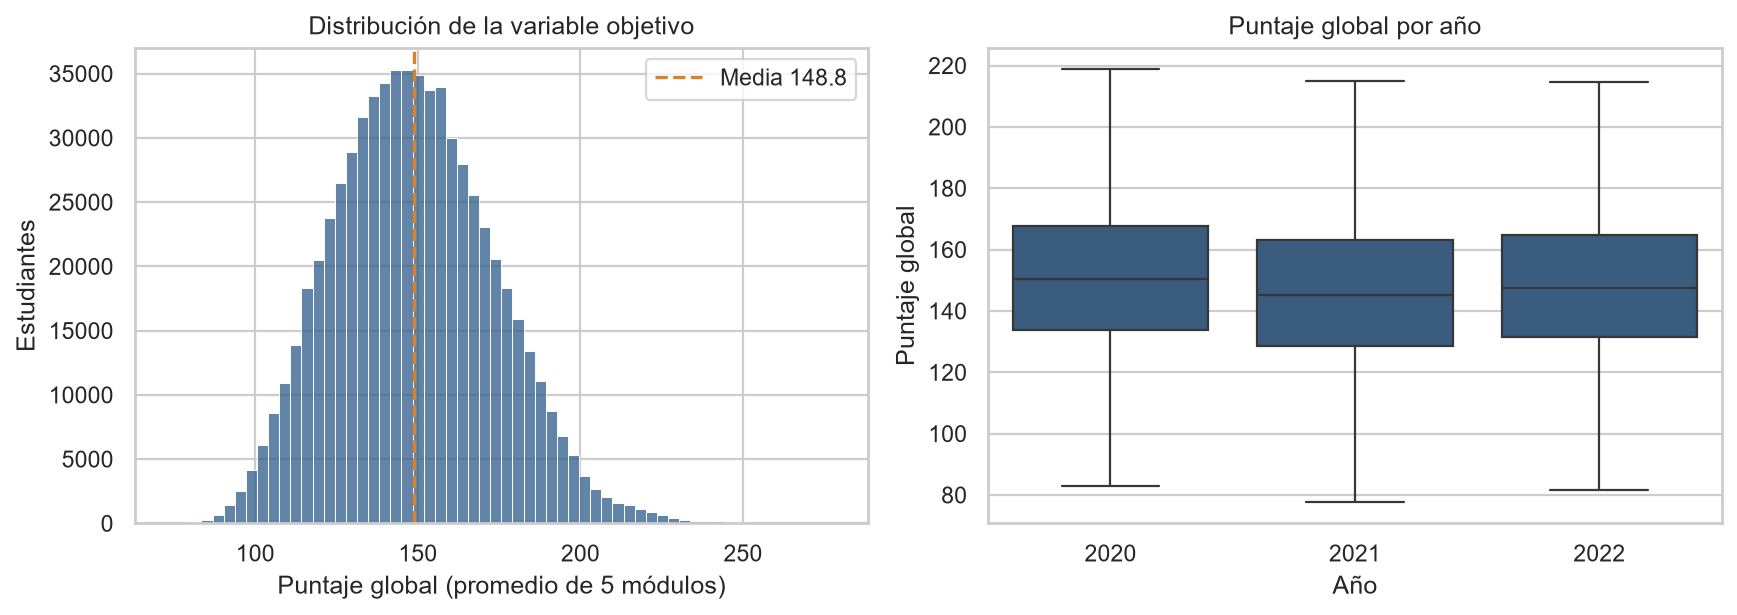

In [11]:
F('fig_01_distribucion_objetivo.png')

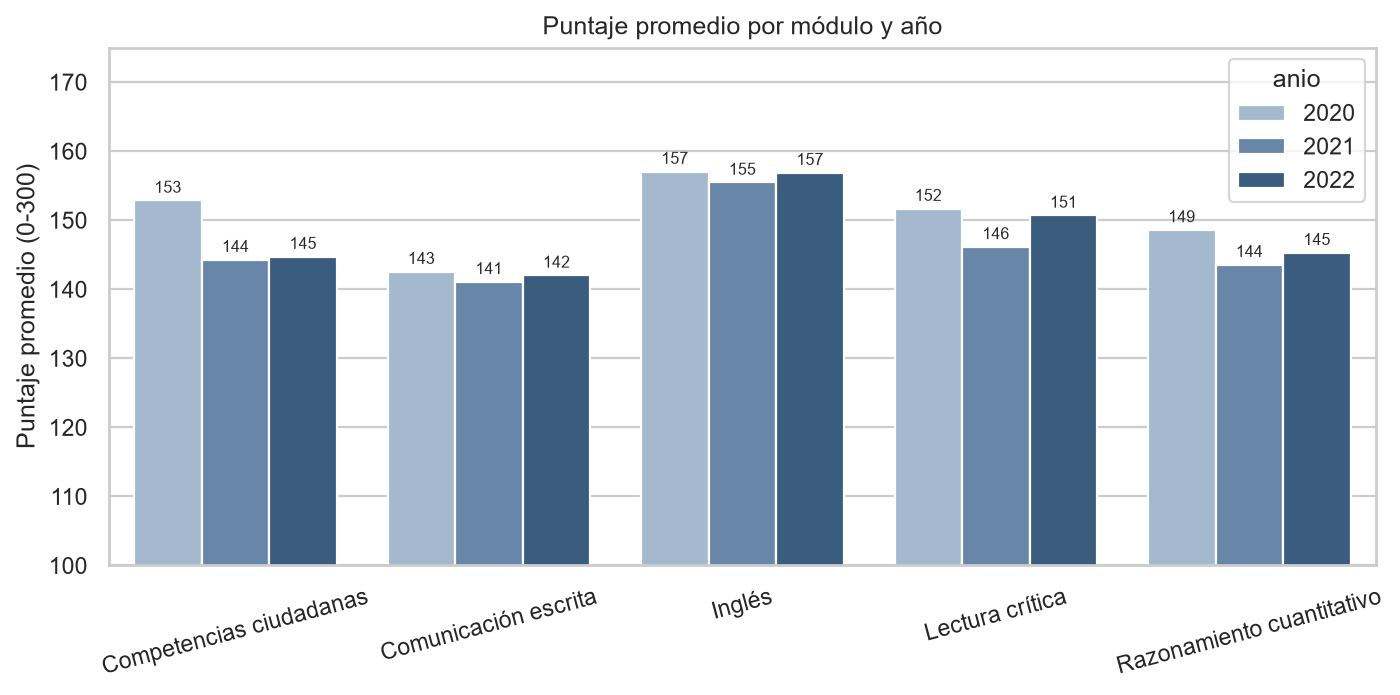

In [12]:
F('fig_02_modulos_por_anio.png')

In [13]:
T('eda_modulos_por_anio.csv')

,anio,Razonamiento cuantitativo,Lectura crítica,Competencias ciudadanas,Inglés,Comunicación escrita,Puntaje global,n_registros
0,2020,148.60,151.69,152.86,157.05,142.55,151.18,242855
1,2021,143.57,146.14,144.29,155.46,141.08,146.58,241168
2,2022,145.29,150.70,144.73,156.89,142.02,148.76,215820


### Objetivo cruzado con región, naturaleza jurídica, estrato y educación de la madre

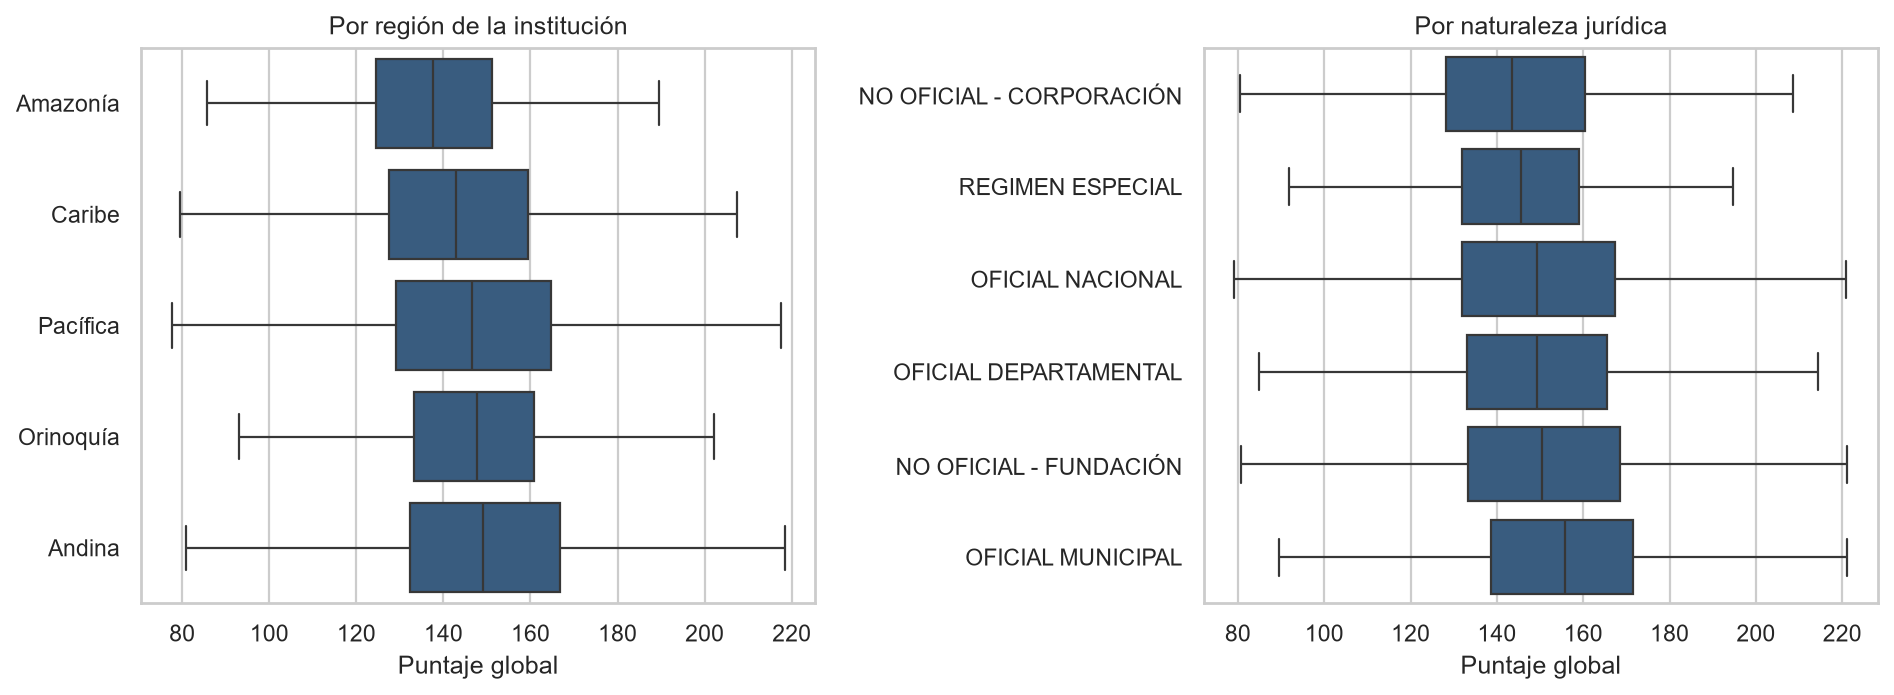

In [14]:
F('fig_03_region_y_origen.png')

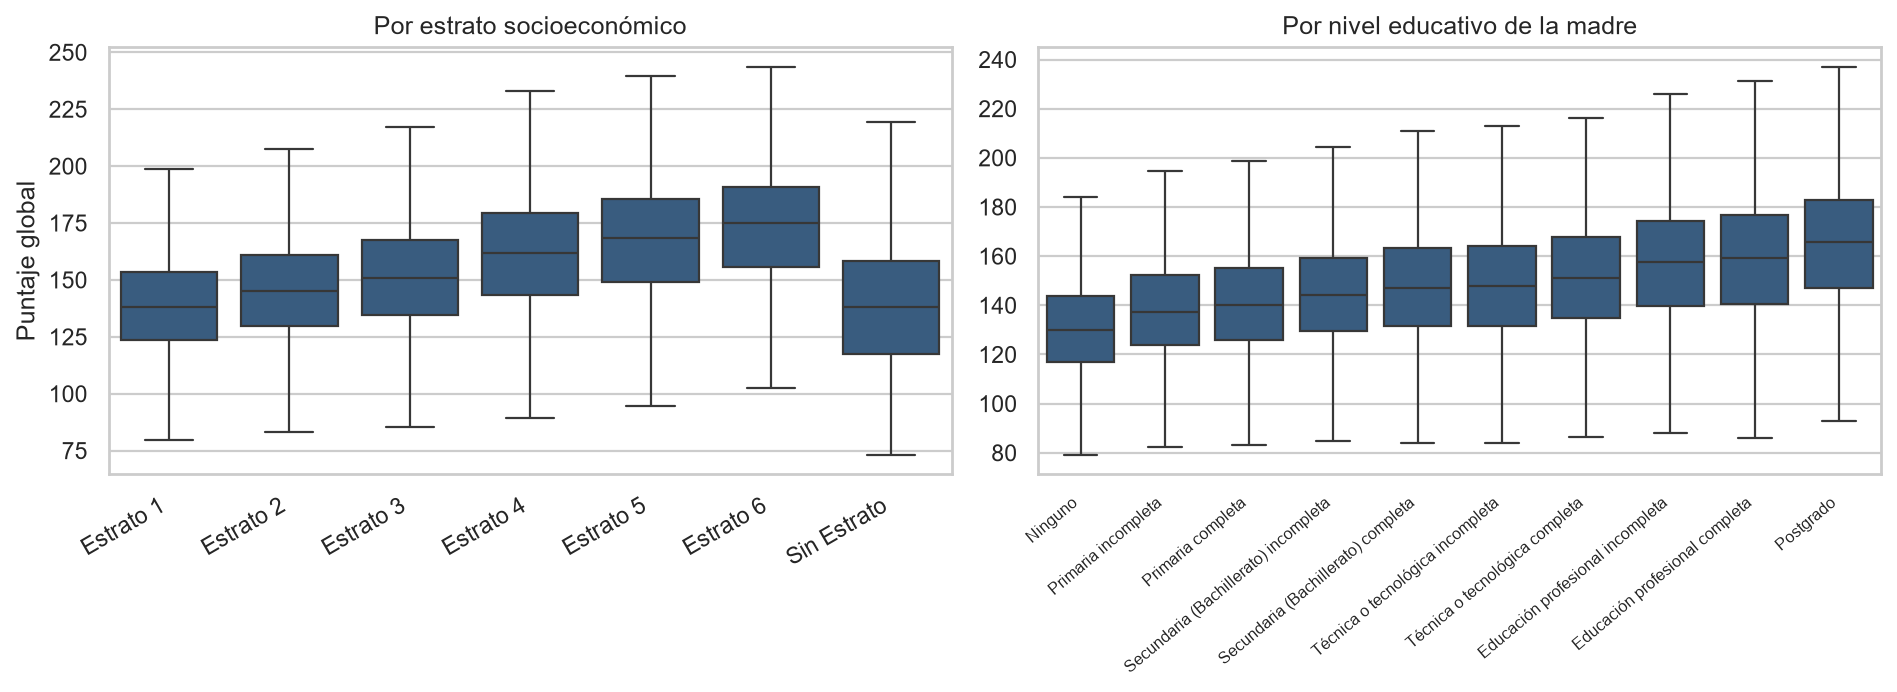

In [15]:
F('fig_04_estrato_y_educacion_madre.png')

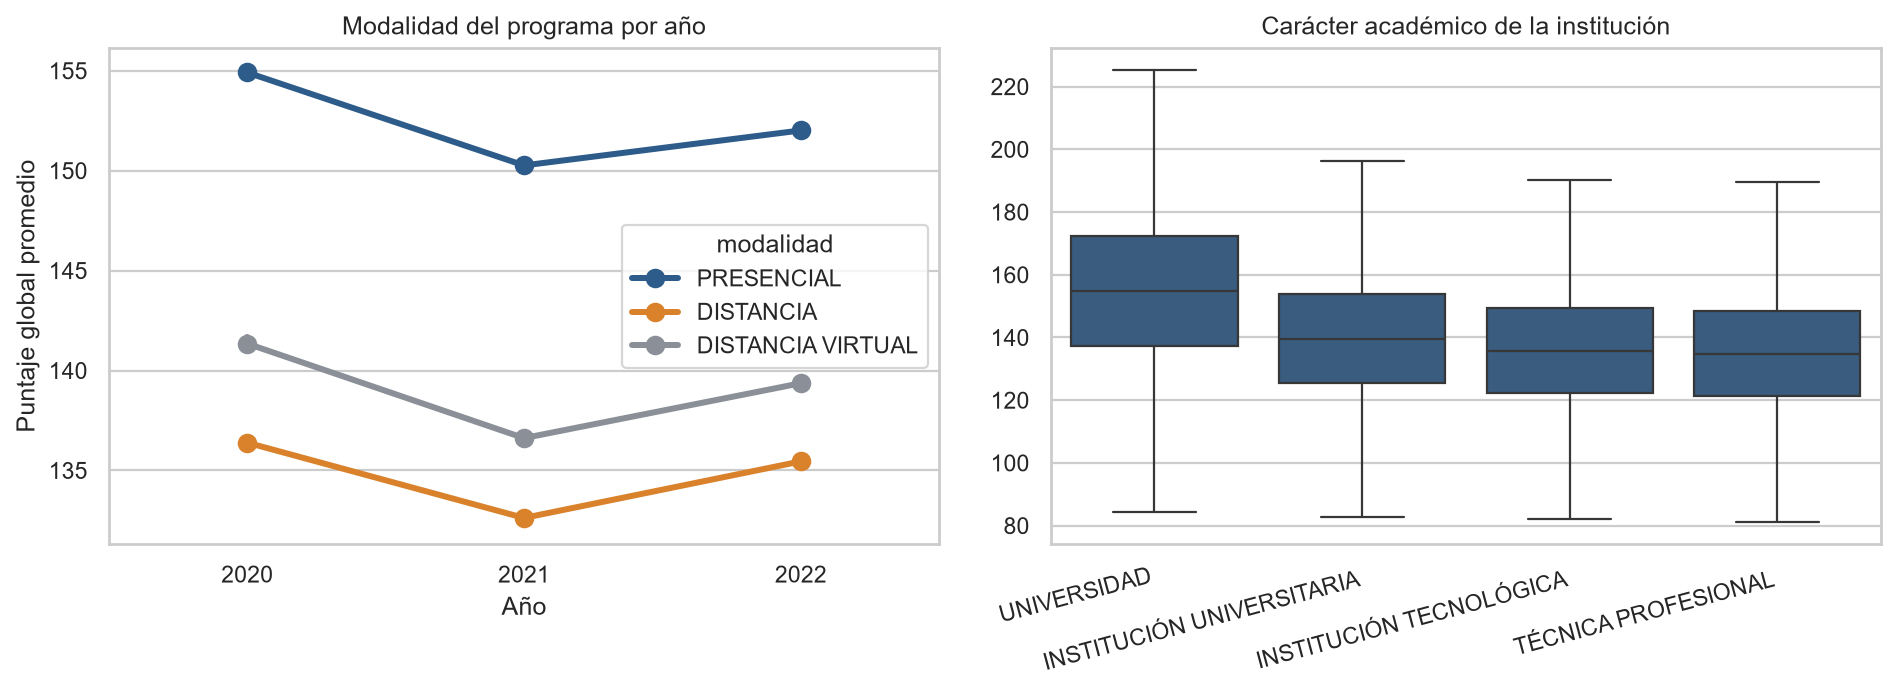

In [16]:
F('fig_05_modalidad_y_caracter.png')

### Tamaño del efecto por variable (Kruskal–Wallis, ε²)

In [17]:
T('eda_kruskal_efectos.csv')

,variable,n,H_kruskal,p_valor,epsilon2,magnitud
0,Valor de matrícula,655138,88590.9,0.000000e+00,0.1352,mediana
1,Educación de la madre,660712,65251.3,0.000000e+00,0.0988,mediana
2,Carácter académico,660712,62047.2,0.000000e+00,0.0939,mediana
3,Educación del padre,660712,59968.0,0.000000e+00,0.0908,mediana
4,Estrato,660712,57493.9,0.000000e+00,0.0870,mediana
5,Modalidad,660712,52874.2,0.000000e+00,0.0800,mediana
6,Horas de trabajo,649311,17548.6,0.000000e+00,0.0270,pequeña
7,Tiene internet,654900,16059.3,0.000000e+00,0.0245,pequeña
8,Tiene computador,639925,15381.1,0.000000e+00,0.0240,pequeña
9,Naturaleza jurídica,660712,9018.0,0.000000e+00,0.0136,pequeña


### Brecha de género por módulo

In [18]:
T('eda_genero_modulos.csv')

,modulo,media_mujeres,media_hombres,dif_hombres_menos_mujeres,ic95_inf,ic95_sup,d_cohen,p_mannwhitney
0,Razonamiento cuantitativo,140.70,155.25,14.55,14.39,14.71,0.458,0.000000e+00
1,Lectura crítica,149.11,151.82,2.71,2.56,2.86,0.090,1.477670e-272
2,Competencias ciudadanas,146.06,151.48,5.42,5.25,5.58,0.166,0.000000e+00
3,Inglés,154.61,160.75,6.14,5.98,6.29,0.196,0.000000e+00
4,Comunicación escrita,141.94,141.79,-0.14,-0.31,0.02,-0.004,7.136109e-12
5,Puntaje global,146.48,152.22,5.73,5.61,5.85,0.234,0.000000e+00


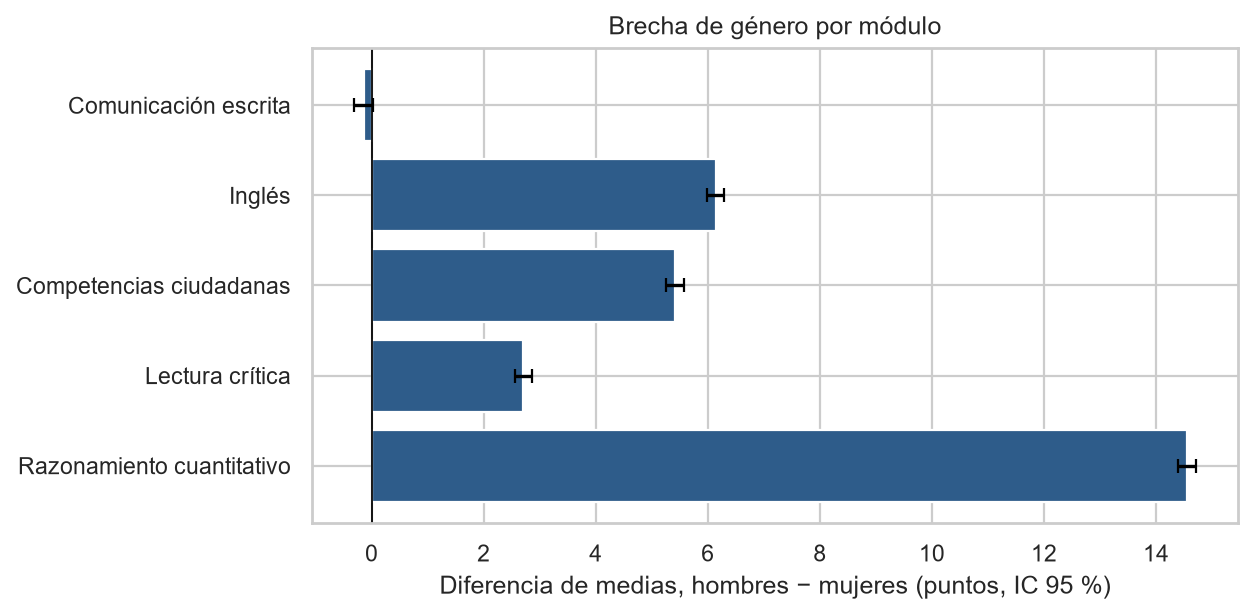

In [19]:
F('fig_06_brecha_genero_modulos.png')

### Interacciones y correlaciones

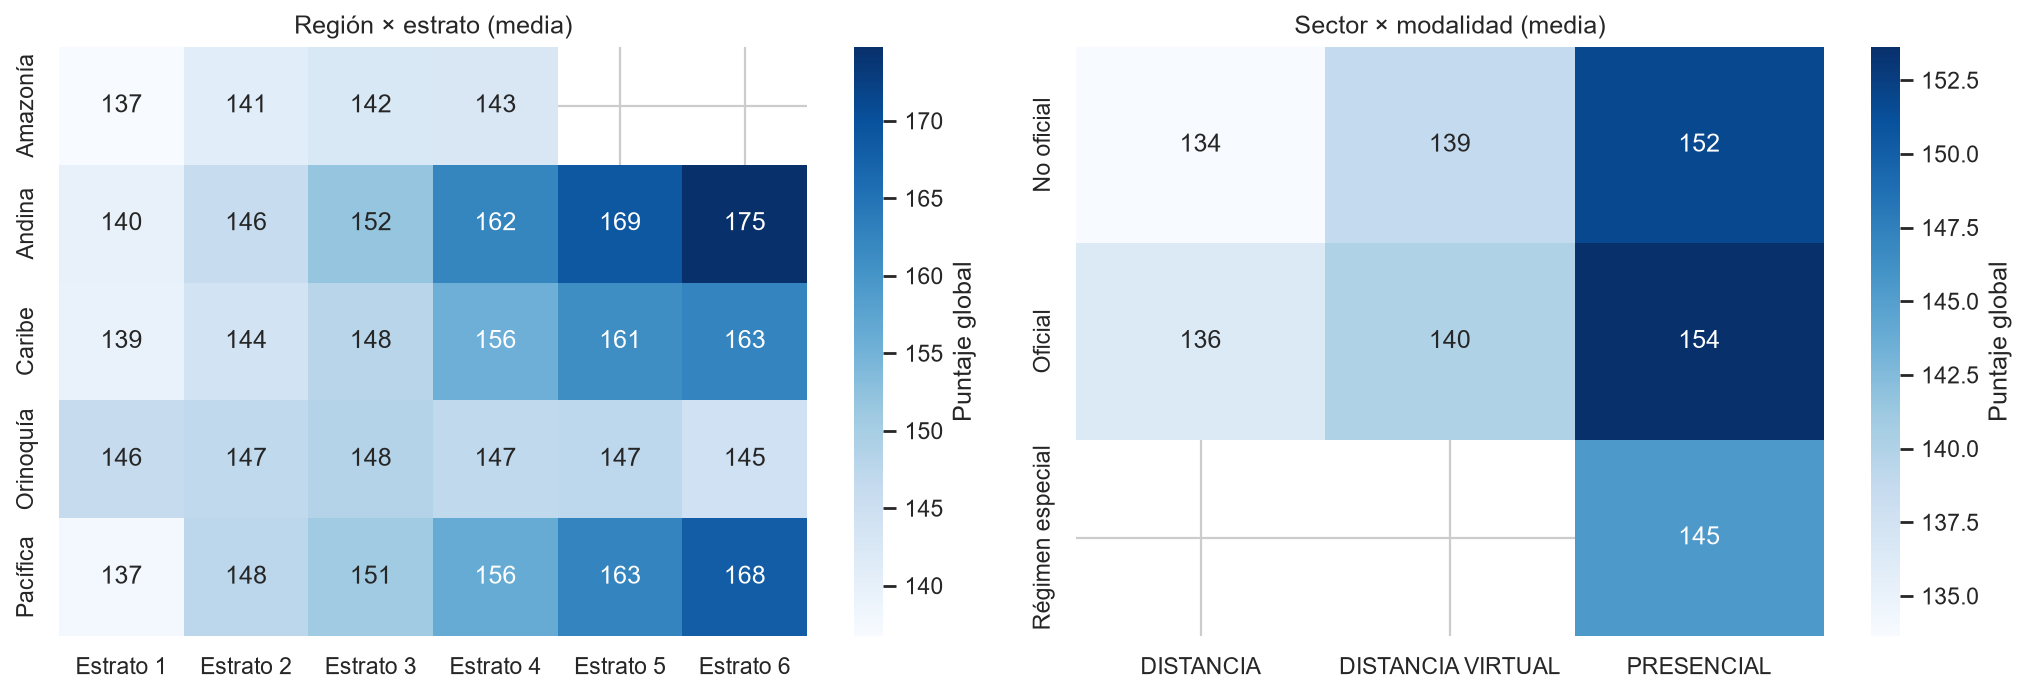

In [20]:
F('fig_07_heatmaps_region_estrato_sector_modalidad.png')

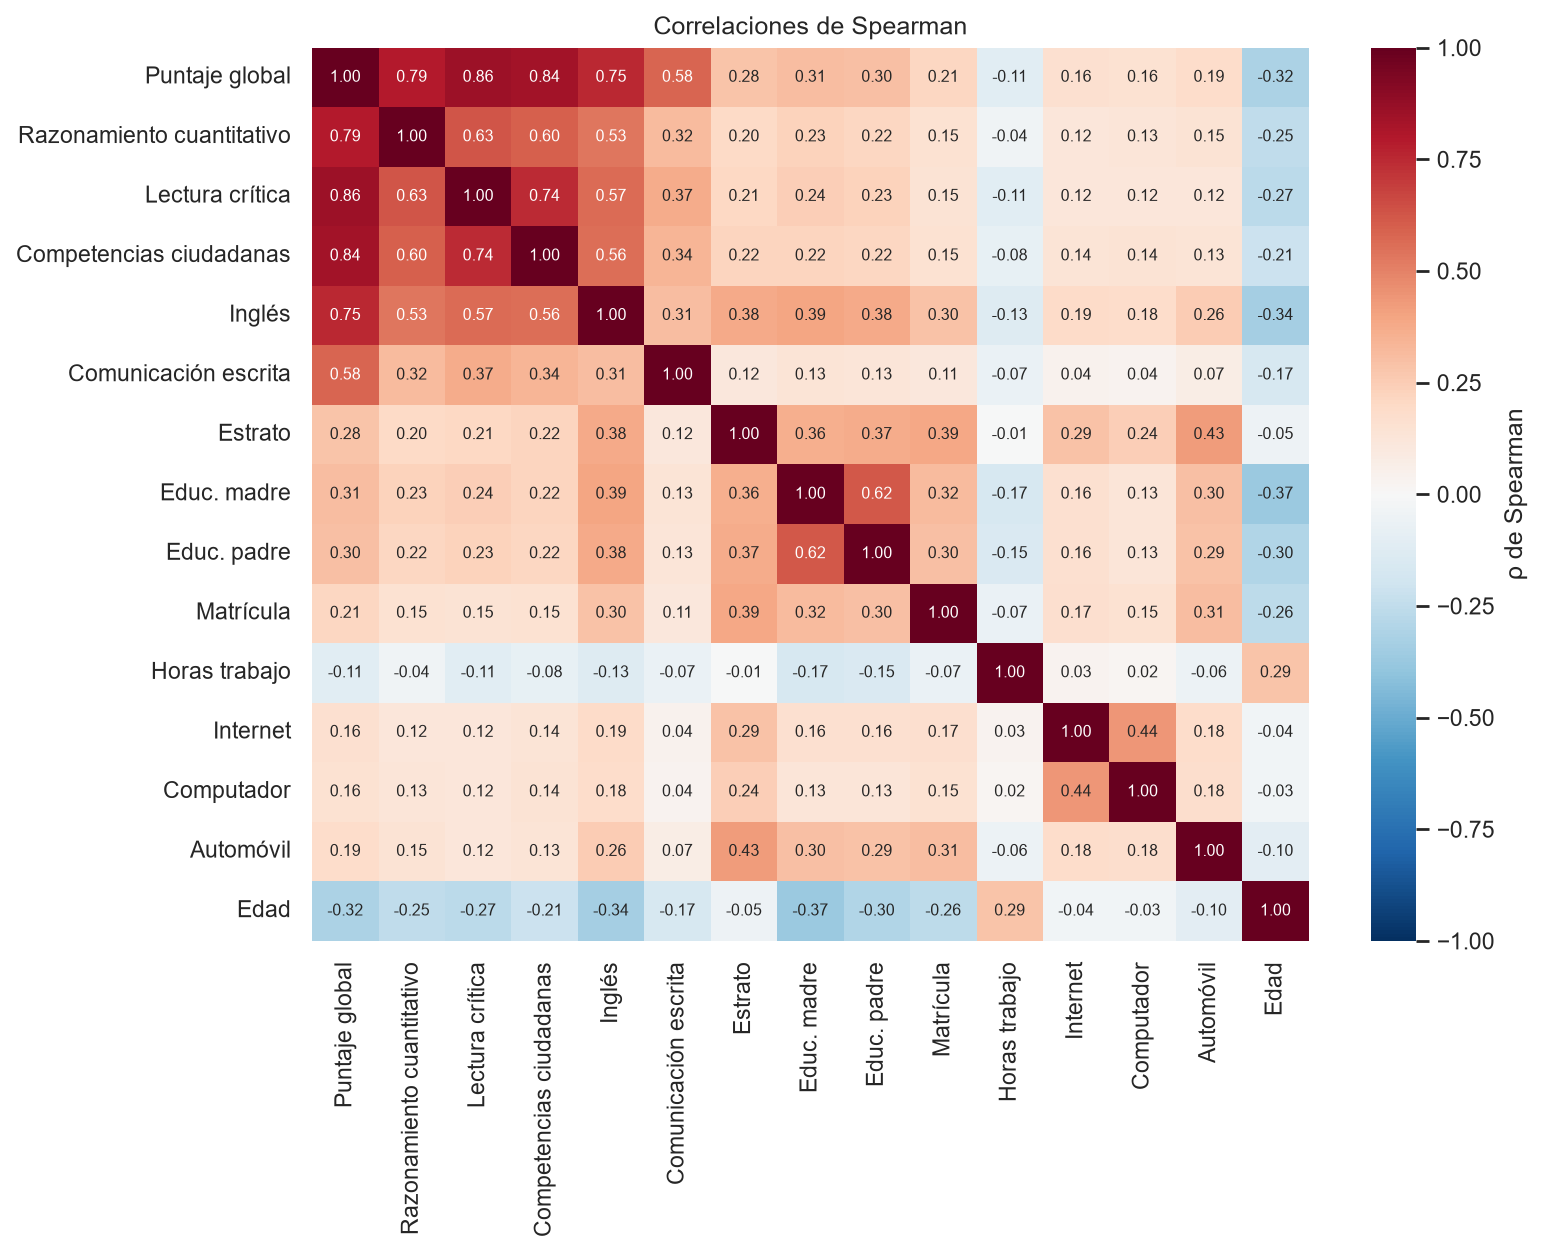

In [21]:
F('fig_08_correlaciones.png')

### Instituciones y departamentos

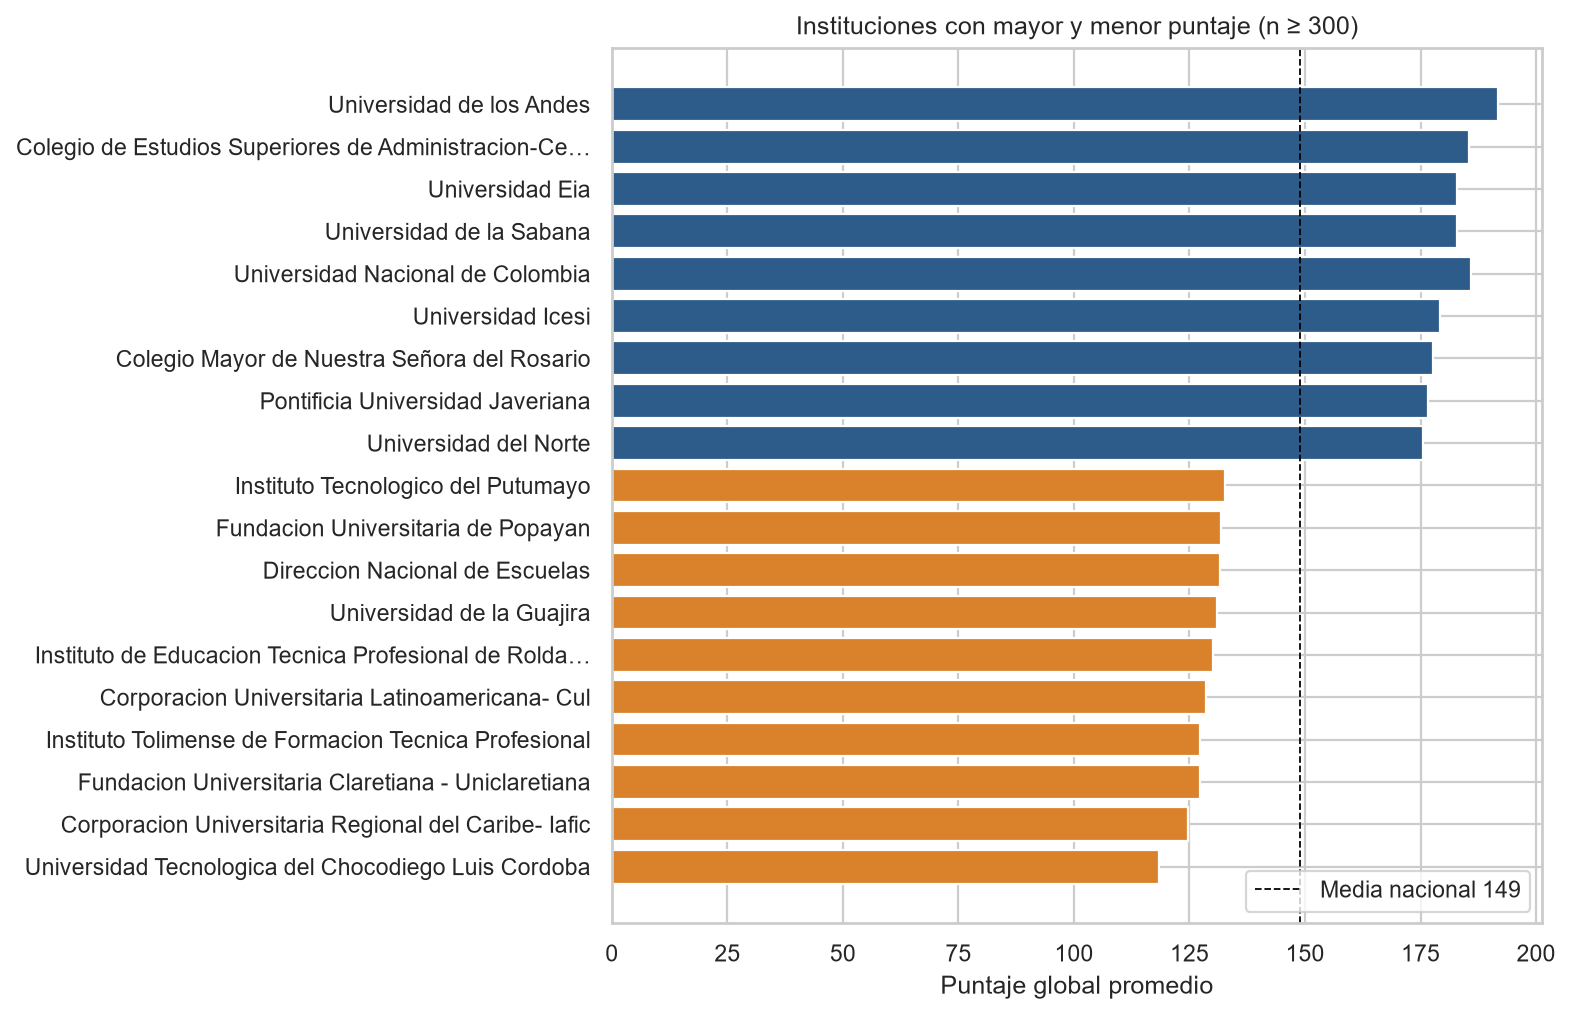

In [22]:
F('fig_09_instituciones_top_bottom.png')

In [23]:
T('eda_departamentos.csv')

,depto_inst,region_inst,count,mean
0,CHOCO,Pacífica,5139,120.4
1,LA GUAJIRA,Caribe,4697,131.0
2,PUTUMAYO,Amazonía,592,132.6
3,SUCRE,Caribe,8668,138.1
4,CAQUETA,Amazonía,2323,139.4
5,CESAR,Caribe,6198,140.1
6,CASANARE,Orinoquía,525,141.2
7,CORDOBA,Caribe,10354,141.9
8,BOLIVAR,Caribe,19470,143.4
9,TOLIMA,Andina,10700,143.5


### Modelo lineal múltiple (efectos ajustados)

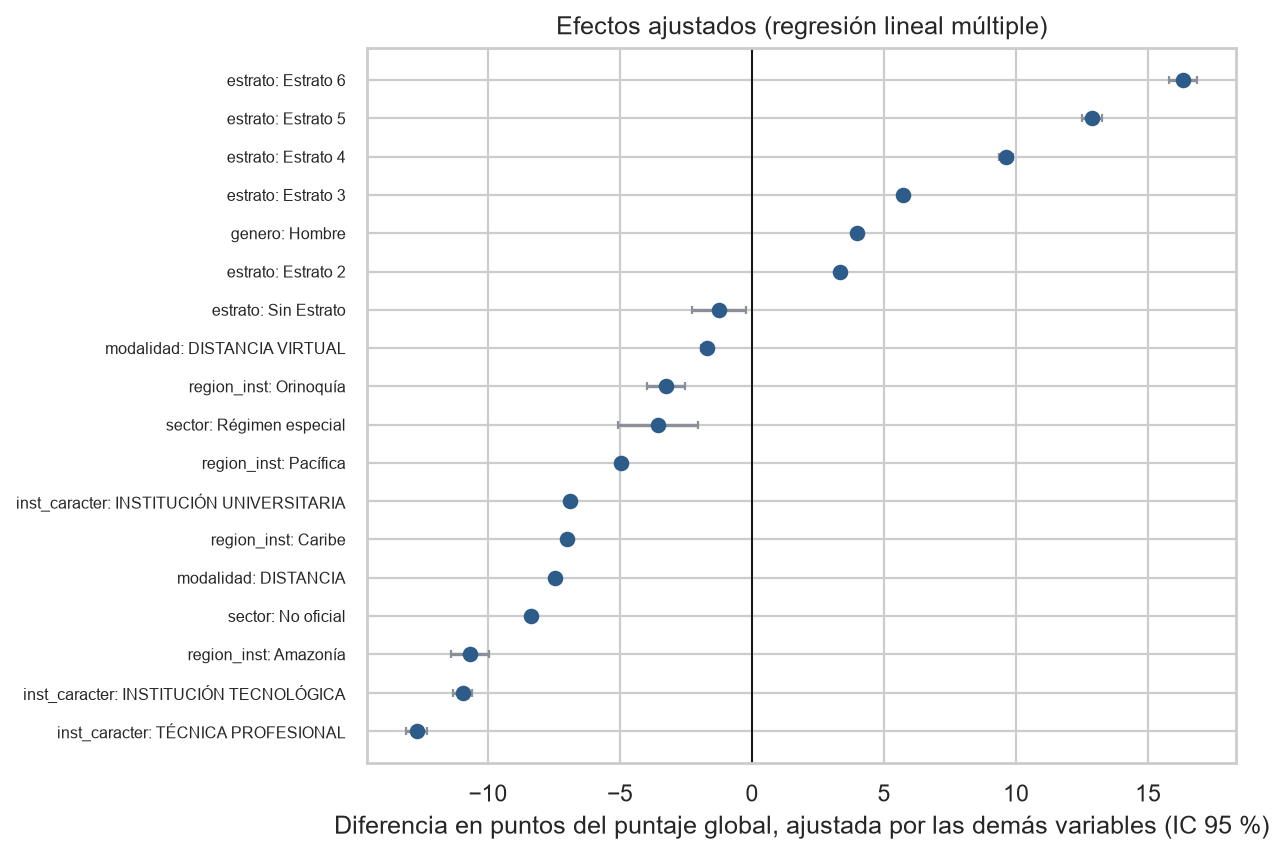

In [24]:
F('fig_10_efectos_ajustados.png')

In [25]:
T('eda_ols_aporte_bloques.csv')

,bloque,delta_R2_al_quitarlo
0,Carácter académico,0.0164
1,Estrato,0.0130
2,Edad,0.0115
3,Sector,0.0110
4,Región,0.0109
5,Educación de los padres,0.0102
6,Trabajo y matrícula,0.0095
7,Modalidad,0.0087
8,Género,0.0060
9,Conectividad,0.0049


## 5. Protocolo de evaluación y líneas base

In [26]:
T('protocolo_particion.csv')

,conjunto,n,pct_bajo_desempeno
0,Entrenamiento (2020-2021),467356.0,24.8
1,Prueba (2022),193356.0,24.4
2,Umbral de bajo desempeño (P25 del entrenamiento),NaN,131.0


In [27]:
T('protocolo_lineas_base.csv')

,linea_base,RMSE,MAE,R2,AUC_ROC_bajo_desempeno,recall_en_25pct_alertado,precision_en_25pct_alertado
0,B0. Media global,24.22,19.47,-0.0000,0.5000,0.2500,0.2442
1,B1. Media por estrato,23.10,18.51,0.0903,0.6090,0.3501,0.3420
2,B2. Media por carácter académico,23.11,18.50,0.0889,0.6117,0.3638,0.3553
3,B3. Media por institución,20.46,16.19,0.2865,0.7123,0.4280,0.4181
4,B4. Regresión lineal múltiple,20.91,16.58,0.2545,0.7190,0.4546,0.4441


Criterios de éxito y definición completa en `docs/protocolo_evaluacion.md`; recomendaciones en `docs/hallazgos_y_recomendaciones.md`.